In [19]:
import pandas as pd
df = pd.read_csv("netflix_cleaned.csv")
df.shape

(8786, 16)

In [20]:
type_counts = df["type"].value_counts()
type_counts

type
Movie      6123
TV Show    2663
Name: count, dtype: int64

In [21]:
total = len(df)
total

8786

In [22]:
type_percent = (df["type"].value_counts(normalize=True) * 100).round(2)
type_percent

type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64

In [23]:
print("Total titles:", total)
print("Movies:", type_counts["Movie"])
print("TV Shows:", type_counts["TV Show"])

Total titles: 8786
Movies: 6123
TV Shows: 2663


In [24]:
type_counts.sum() == total

np.True_

In [25]:
import matplotlib.pyplot as plt


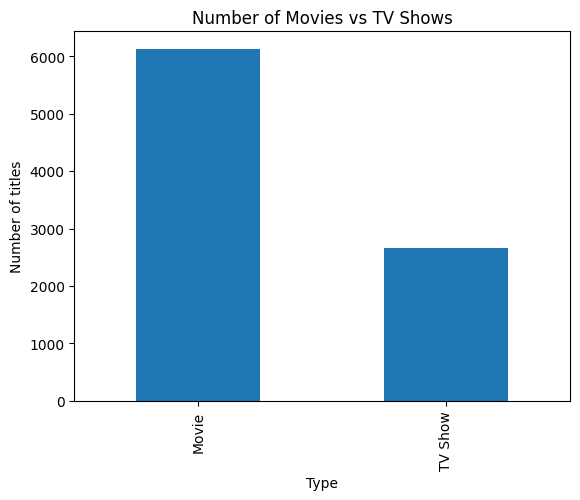

In [26]:
type_counts.plot(kind="bar")
plt.title("Number of Movies vs TV Shows")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.show()

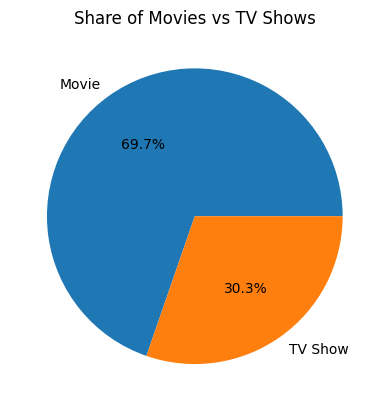

In [27]:
type_counts.plot(kind="pie", autopct="%1.1f%%")
plt.title("Share of Movies vs TV Shows")
plt.ylabel("")
plt.show()

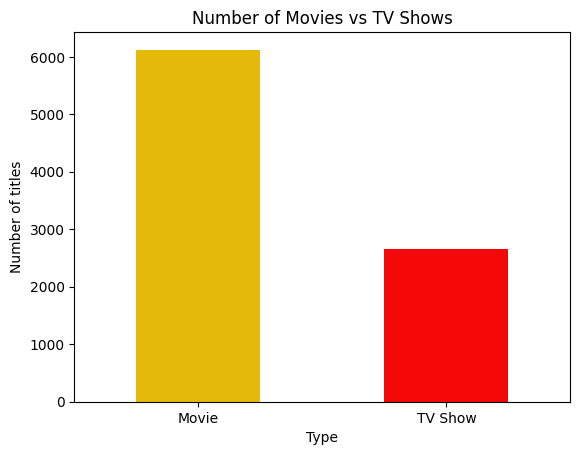

In [28]:
type_counts.plot(kind="bar", color=["#E5B909", "#F40707"])
plt.title("Number of Movies vs TV Shows")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.xticks(rotation=0)
plt.show()

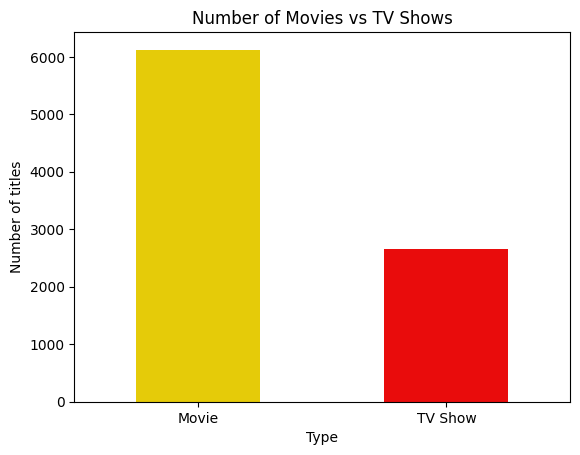

In [29]:
type_counts.plot(kind="bar", color=["#E5CB09", "#E90C0C"])
plt.title("Number of Movies vs TV Shows")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.xticks(rotation=0)
plt.savefig("type_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
ratio = type_counts["Movie"] / type_counts["TV Show"]
print("Movies per 1 TV Show:", round(ratio, 2))

Movies per 1 TV Show: 2.3


In [31]:
gap = type_percent["Movie"] - type_percent["TV Show"]
print("Movies lead TV Shows by", round(gap, 2), "percentage points")

Movies lead TV Shows by 39.38 percentage points


In [32]:
by_year = pd.crosstab(df["year_added"], df["type"], normalize="index") * 100
by_year.round(1).tail(8)

type,Movie,TV Show
year_added,,
2014,79.2,20.8
2015,68.3,31.7
2016,58.9,41.1
2017,70.5,29.5
2018,75.0,25.0
2019,70.6,29.4
2020,68.3,31.7
2021,66.3,33.7


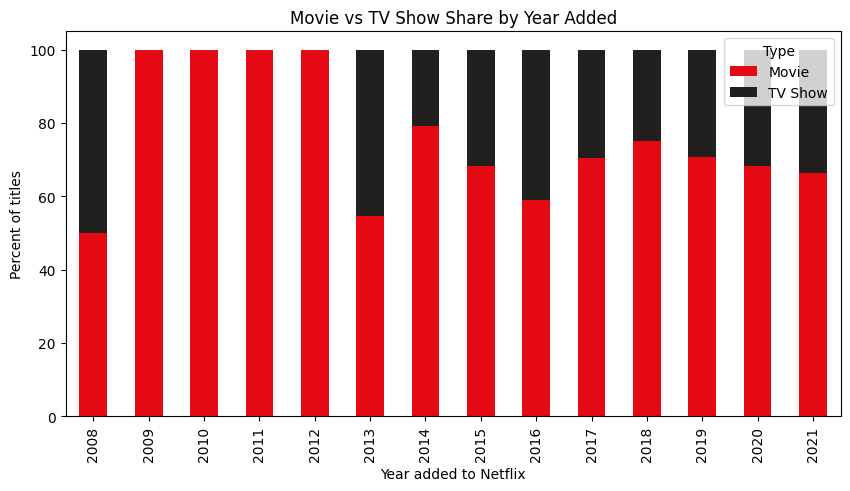

In [33]:
by_year.plot(kind="bar", stacked=True, color=["#E50914", "#221F1F"], figsize=(10, 5))
plt.title("Movie vs TV Show Share by Year Added")
plt.xlabel("Year added to Netflix")
plt.ylabel("Percent of titles")
plt.legend(title="Type")
plt.savefig("type_share_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
print("Highest Movie share:", by_year["Movie"].idxmax(), round(by_year["Movie"].max(), 1), "%")
print("Lowest Movie share:", by_year["Movie"].idxmin(), round(by_year["Movie"].min(), 1), "%")


Highest Movie share: 2009 100.0 %
Lowest Movie share: 2008 50.0 %


In [35]:
df["year_added"].value_counts().sort_index()


year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2013
2020    1879
2021    1498
Name: count, dtype: int64

In [36]:
by_year["Movie"].round(1)

year_added
2008     50.0
2009    100.0
2010    100.0
2011    100.0
2012    100.0
2013     54.5
2014     79.2
2015     68.3
2016     58.9
2017     70.5
2018     75.0
2019     70.6
2020     68.3
2021     66.3
Name: Movie, dtype: float64

# Content Type Analysis: Key Findings

## Overview
- Total titles analyzed: 8,786
- Movies: 6,123 (69.69%)
- TV Shows: 2,663 (30.31%)

## Key Findings
1. Movies make up about 70% of the catalog, roughly 2.3 Movies for every 1 TV Show.
2. Movies lead TV Shows by 39.38 percentage points.
3. Among years with at least 100 titles added (2016 to 2021), the Movie share was highest in 2018 (75.0%) and lowest in 2016 (58.9%).
4. The Movie share dipped in 2016 (58.9%), rose to 75.0% in 2018, and then eased gradually to 66.3% in 2021. TV Shows grew from about 25% of new titles in 2018 to about 34% in 2021, so Netflix has been adding TV Shows at a faster rate in recent years.

## Caveat
- Years 2008 to 2013 have very few titles (fewer than 15 each), so their percentages are unreliable. For example, 2009 shows 100% Movies, but it is based on only 2 titles. These years were excluded when finding the highest and lowest shares.

## Charts
- `type_distribution.png`: bar chart of Movie and TV Show counts
- `type_share_by_year.png`: stacked chart of Movie and TV Show share by year added

## Conclusion
Netflix's catalog is dominated by Movies, but the gap has narrowed since 2018 as more TV Shows were added.

![Type distribution](type_distribution.png)
![Share by year](type_share_by_year.png)